**Universidade Federal do Rio Grande do Norte**

**Disciplina:** PPGEEC2327 - Tópicos Especiais em Processamento Inteligente da Informação

**Discente:** José Augusto Agripino de Oliveira

# Picking automático de semblance com K-means

Laboratório: [Automatic Semblance Picking using Clustering Algorithms](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Cluster/Chapter.Cluster1/lab.html) (Y. Chen).

Na análise de velocidades, procura-se no espectro de semblance a velocidade de empilhamento $V(t_0)$ que passa pelos máximos de energia. O lab automatiza esse picking: os pontos de alta semblance são agrupados em $K$ clusters, e os **centroides**, ligados em ordem de tempo, formam a curva de velocidade. O K-means minimiza

$$J=\sum_{k=1}^{K}\sum_{\mathbf x\in c_k}\|\mathbf x-\boldsymbol\mu_k\|^2,\qquad \mathbf x=(ix,\,iz),$$

alternando a atribuição de cada ponto ao centroide mais próximo e o recálculo de cada centroide como a média dos seus pontos.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from scipy.cluster.vq import kmeans2
from IPython.display import Markdown, display

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})

## 1. Espectro de velocidades e *thresholding*

O espectro tem 3521 tempos (1 ms) por 381 velocidades (1400 a 5200 m/s, passo de 10 m/s). Aplica-se um filtro de mediana 3×3 e mantêm-se só os pontos acima do limiar `prctile(prctile(vel_spec,90),90)`.

limiar = 63.51 (máximo do espectro = 76.42)
pontos com thresholding: 39,413 (2.9 % do painel)
pontos sem thresholding: 1,140,328 (85.0 % do painel)


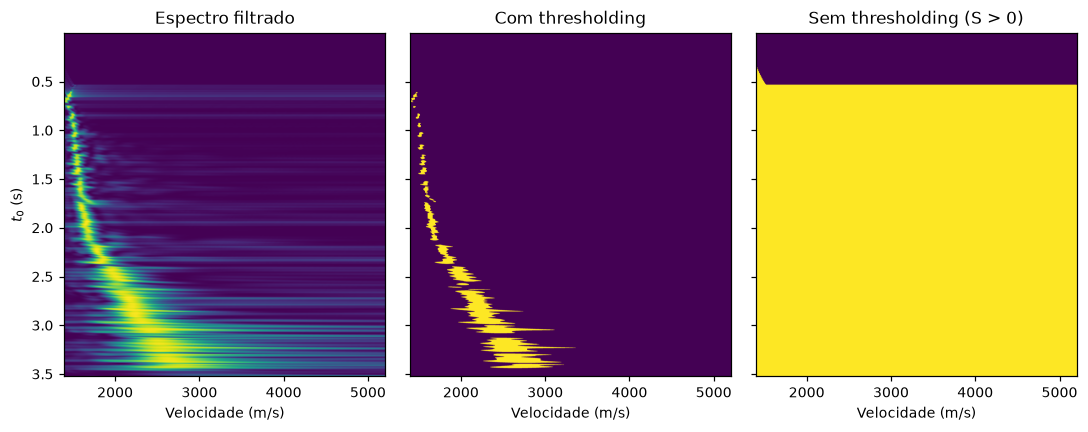

In [2]:
NT, NV = 3521, 381
bruto = np.fromfile(Path('K_Means_Method/vel_spec.bin775'), dtype='<f4').reshape((NT, NV), order='F')
S = median_filter(bruto.astype(float), size=3, mode='constant')          # medfilt2(vel_spec,[3,3])

vel = lambda ix: 1400 + (ix - 1) * 10          # índice (base 1) -> m/s
tempo = lambda iz: iz * 0.001                  # índice (base 1) -> s
EXT = [vel(0.5), vel(NV + 0.5), tempo(NT + 0.5), tempo(0.5)]

def limiar(p):
    # prctile(prctile(S,p),p); o método 'hazen' é o do prctile do MATLAB
    return np.percentile(np.percentile(S, p, axis=0, method='hazen'), p, method='hazen')

def pontos(mascara):
    # conjunto de treino: uma linha (ix, iz) por ponto selecionado
    ix, iz = np.nonzero(mascara.T)
    return np.c_[ix + 1, iz + 1].astype(float)

th = limiar(90)
X_th = pontos(S > th)          # com thresholding
X_sem = pontos(S > 0)          # thresholding comentado (limiar nulo)
print(f'limiar = {th:.2f} (máximo do espectro = {S.max():.2f})')
print(f'pontos com thresholding: {len(X_th):,} ({100 * len(X_th) / S.size:.1f} % do painel)')
print(f'pontos sem thresholding: {len(X_sem):,} ({100 * len(X_sem) / S.size:.1f} % do painel)')

fig, ax = plt.subplots(1, 3, figsize=(10, 4), sharey=True)
for a, img, t in zip(ax, [S, S > th, S > 0], ['Espectro filtrado', 'Com thresholding', 'Sem thresholding (S > 0)']):
    a.imshow(img, aspect='auto', extent=EXT); a.set_title(t); a.set_xlabel('Velocidade (m/s)')
ax[0].set_ylabel('$t_0$ (s)'); plt.tight_layout(); plt.show()

## 2. K-means

$K=15$, 15 iterações e centroides iniciais igualmente espaçados na diagonal do painel. Um cluster que fica vazio vai para (0, 0), como no original; ele é descartado da curva de velocidade.

Como não há picking de referência, a qualidade é medida pela **energia capturada**: soma da semblance ao longo da curva dividida pela soma dos máximos de cada tempo (100 % = a curva passa por todos os máximos). O intervalo de tempo avaliado é o mesmo em todos os testes.

In [3]:
def kmeans(X, K=15, maxiter=15, pesos=None):
    # Tradução do K_mean_cluster.m. Com pesos=None, todos os pontos valem 1.
    w = np.ones(len(X)) if pesos is None else pesos
    c = np.outer(np.arange(1, K + 1), [NV // (K + 1), NT // (K + 1)]).astype(float)
    J = []
    for _ in range(maxiter):
        d = np.stack([((X - ck) ** 2).sum(axis=1) for ck in c], axis=1)   # distâncias ao quadrado
        y = d.argmin(axis=1)
        J.append((w * d[np.arange(len(X)), y]).sum())
        n = np.bincount(y, weights=w, minlength=K)
        soma = np.stack([np.bincount(y, weights=w * X[:, j], minlength=K) for j in (0, 1)], axis=1)
        c = soma / np.where(n == 0, 1, n)[:, None]
    return c, n > 0, np.array(J)

IZ = np.arange(X_th[:, 1].min(), X_th[:, 1].max() + 1).astype(int)       # tempos avaliados

def curva(c, ativos):
    c = c[ativos]
    return c[np.argsort(c[:, 1])]

def energia(c, ativos):
    p = curva(c, ativos)
    ix = np.rint(np.interp(IZ, p[:, 1], p[:, 0])).astype(int)
    return 100 * S[IZ - 1, ix - 1].sum() / S[IZ - 1].max(axis=1).sum()

def plota(ax, c, ativos, titulo):
    p = curva(c, ativos)
    ax.imshow(S, aspect='auto', extent=EXT)
    ax.plot(vel(p[:, 0]), tempo(p[:, 1]), 'k-', lw=1.8)
    ax.plot(vel(p[:, 0]), tempo(p[:, 1]), 'r*', ms=8)
    ax.set_title(titulo); ax.set_xlabel('Velocidade (m/s)')

## 3. Questão 1: efeito de remover o *thresholding*

> *Comment the "thresholding" procedure in the program and re-run the program. How is the K-means method performs and why?*

Comentar apenas as linhas do limiar deixaria `thres_value` e `vel_spec2` indefinidos. Por isso o teste usa limiar zero: todo ponto com $S>0$ entra no treino. Como controle, testa-se também um K-means sem limiar em que cada ponto é **ponderado pela semblance**.

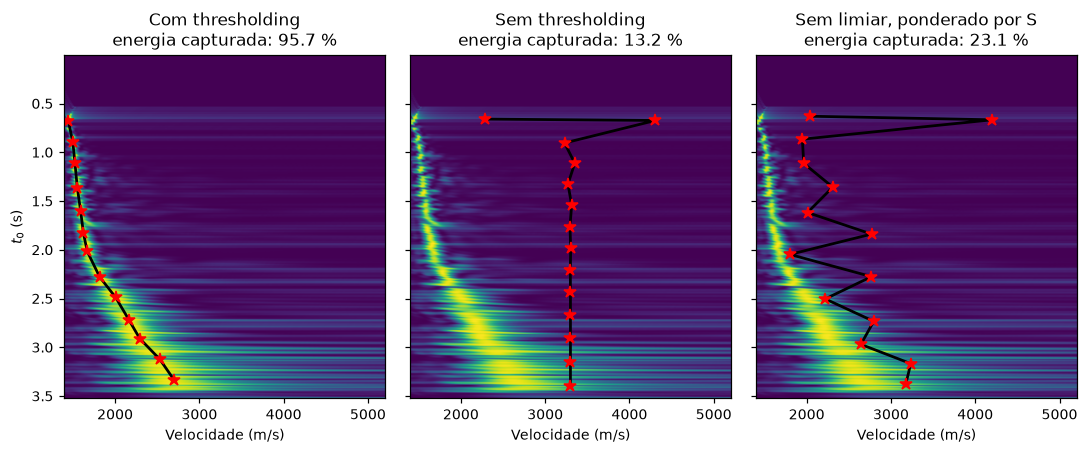

teste                          clusters ativos     V mín-máx (m/s)   energia
Com thresholding                            13         1444 - 2699     95.7%
Sem thresholding                            14         2290 - 4307     13.2%
Sem limiar, ponderado por S                 14         1801 - 4202     23.1%


In [4]:
testes = {
    'Com thresholding': kmeans(X_th),
    'Sem thresholding': kmeans(X_sem),
    'Sem limiar, ponderado por S': kmeans(X_sem, pesos=S.T[S.T > 0]),
}
fig, ax = plt.subplots(1, 3, figsize=(10, 4.2), sharey=True)
for a, (nome, (c, at, J)) in zip(ax, testes.items()):
    plota(a, c, at, f'{nome}\nenergia capturada: {energia(c, at):.1f} %')
ax[0].set_ylabel('$t_0$ (s)'); plt.tight_layout(); plt.show()

print(f"{'teste':30s}{'clusters ativos':>16s}{'V mín-máx (m/s)':>20s}{'energia':>10s}")
for nome, (c, at, J) in testes.items():
    v = vel(c[at, 0])
    print(f'{nome:30s}{at.sum():>16d}{f"{v.min():.0f} - {v.max():.0f}":>20s}{energia(c, at):>9.1f}%')

O limiar usado é um parâmetro. Para ver a sensibilidade a ele, varia-se o percentil:

In [5]:
print(f"{'percentil':>9s}{'limiar':>9s}{'pontos':>11s}{'energia':>10s}")
for p in [50, 70, 80, 90, 95, 98]:
    Xp = pontos(S > limiar(p))
    c, at, _ = kmeans(Xp)
    print(f'{p:>9d}{limiar(p):>9.2f}{len(Xp):>11,d}{energia(c, at):>9.1f}%')

percentil   limiar     pontos   energia


       50     2.06    748,362     13.8%


       70     9.13    339,934     33.7%


       80    28.83    145,121     88.9%
       90    63.51     39,413     95.7%


       95    71.77     13,969     95.2%
       98    74.91      2,317     84.8%


### Resposta

**Sem o thresholding o K-means deixa de fazer o picking.** Os centroides se alinham numa reta vertical no meio do painel (cerca de 3300 m/s), longe da tendência de energia; só os dois mais rasos se afastam dela, perto do início irregular da região com $S>0$. A energia capturada cai de cerca de 96 % para 13 %. Com o limiar, o resultado é consistente com a figura `pick_result.png` do pacote. A única diferença é o trecho da linha preta que, naquela figura, sobe até 1400 m/s em 0 s: são os dois clusters vazios, parados em (0, 0), que o MATLAB também desenha e que aqui são descartados.

**Por quê:**

1. **O K-means só enxerga a posição dos pontos.** O atributo é $(ix, iz)$; o valor da semblance não entra na distância nem na média. A informação de energia só chega ao algoritmo pela escolha de quais pontos participam, e é o limiar que faz essa escolha.
2. **Sem o limiar, os pontos preenchem um retângulo quase uniforme.** A melhor partição de um retângulo uniforme, alto e estreito em índices (3521 × 381), é fatiá-lo no tempo, com cada centroide no centro de sua fatia, isto é, na velocidade central. O resultado descreve a geometria do painel, não a geologia.
3. **Com o limiar, restam cerca de 3 % dos pontos,** concentrados ao longo da tendência de velocidades. Aí a média de cada cluster cai sobre a faixa de energia.

**Ponderar pela semblance não basta.** A curva se desloca em direção à energia, mas oscila e continua ruim: os pontos de fundo têm valor baixo, porém são tão numerosos que ainda dominam a média. É preciso eliminá-los. A tabela de percentis confirma: limiar baixo deixa passar o fundo; limiar alto demais (98) deixa poucos pontos e perde partes da tendência. Neste dado, os percentis 90 e 95 funcionam bem.

## 4. Questão 2: como escolher o número de clusters?

> *How to choose the number of clusters?*

O artigo do lab ([Chen e Schuster](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.Cluster/Chapter.Cluster1/autosembpick.pdf)) propõe aumentar $K$ até o resíduo $J$ deixar de cair de forma significativa. Para que a comparação não dependa da inicialização na diagonal (que gera clusters vazios), usa-se aqui o k-means++ com 10 reinícios, guardando o de menor $J$. Três critérios são avaliados:

* **resíduo** $J(K)$ e sua redução relativa;
* **energia capturada** pela curva;
* **plausibilidade física**, pela velocidade intervalar da equação de Dix entre picks vizinhos:

$$V_{int}^2=\frac{V_2^2t_2-V_1^2t_1}{t_2-t_1}.$$

A equação de Dix supõe camadas planas e velocidade de empilhamento próxima da RMS, então serve aqui só como verificação grosseira. Ela também é sensível ao espaçamento: quanto mais próximos dois picks no tempo, mais um pequeno erro de velocidade se amplifica em $V_{int}$. Por isso a tabela mostra também o menor intervalo de tempo entre picks vizinhos.

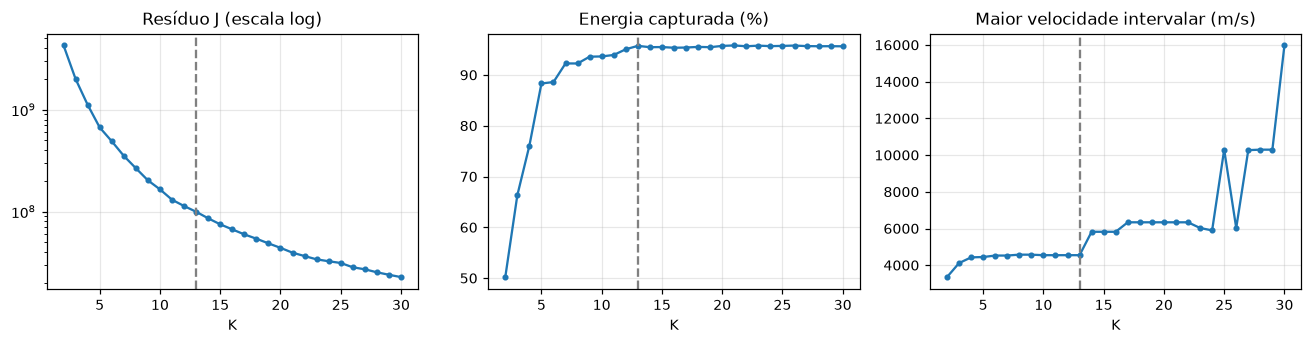

  K          J  queda de J   energia  Vint máx  Δt mín (ms)
  2   4.27e+09           -     50.2%      3353         1134
  3   2.00e+09       53.2%     66.3%      4117          590
  4   1.12e+09       44.2%     76.1%      4428          410
  5   6.69e+08       40.1%     88.3%      4447          385
  6   4.90e+08       26.8%     88.6%      4527          247
  7   3.52e+08       28.2%     92.3%      4527          247
  8   2.66e+08       24.3%     92.3%      4576          158
  9   2.02e+08       24.0%     93.6%      4574          158
 10   1.65e+08       18.4%     93.6%      4547          152
 11   1.31e+08       20.9%     93.9%      4547          152
 12   1.13e+08       13.2%     95.1%      4547          152
 13   9.95e+07       12.1%     95.7%      4547          152
 14   8.58e+07       13.8%     95.5%      5822           96
 15   7.49e+07       12.7%     95.5%      5822           96
 16   6.68e+07       10.8%     95.4%      5822           96
 17   5.96e+07       10.7%     95.4%    

In [6]:
def kmeans_pp(X, K, reinicios=10):
    melhor = None
    for s in range(reinicios):
        c, y = kmeans2(X, K, iter=100, minit='++', seed=s)
        J = ((X - c[y]) ** 2).sum()
        if melhor is None or J < melhor[0]:
            melhor = (J, c, np.bincount(y, minlength=K) > 0)
    return melhor

def dix_max(c, ativos):
    p = curva(c, ativos)
    v, t = vel(p[:, 0]), tempo(p[:, 1])
    v2 = np.diff(v ** 2 * t) / np.diff(t)
    return np.sqrt(v2.max())

def dt_min(c, ativos):
    # menor intervalo de tempo entre picks vizinhos, em ms
    return 1000 * np.diff(tempo(curva(c, ativos)[:, 1])).min()

Ks = np.arange(2, 31)
res = {K: kmeans_pp(X_th, K) for K in Ks}
J = np.array([res[K][0] for K in Ks])
E = np.array([energia(*res[K][1:]) for K in Ks])
D = np.array([dix_max(*res[K][1:]) for K in Ks])
T = np.array([dt_min(*res[K][1:]) for K in Ks])
queda = np.r_[np.nan, 100 * (1 - J[1:] / J[:-1])]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, y, t in zip(ax, [J, E, D], ['Resíduo J (escala log)', 'Energia capturada (%)', 'Maior velocidade intervalar (m/s)']):
    a.plot(Ks, y, 'o-', ms=3); a.set_title(t); a.set_xlabel('K'); a.grid(alpha=.3)
    a.axvline(13, color='gray', ls='--')
ax[0].set_yscale('log'); plt.tight_layout(); plt.show()

print(f"{'K':>3s}{'J':>11s}{'queda de J':>12s}{'energia':>10s}{'Vint máx':>10s}{'Δt mín (ms)':>13s}")
for i, K in enumerate(Ks):
    q = '-' if i == 0 else f'{queda[i]:.1f}%'
    print(f'{K:>3d}{J[i]:>11.2e}{q:>12s}{E[i]:>9.1f}%{D[i]:>10.0f}{T[i]:>13.0f}')

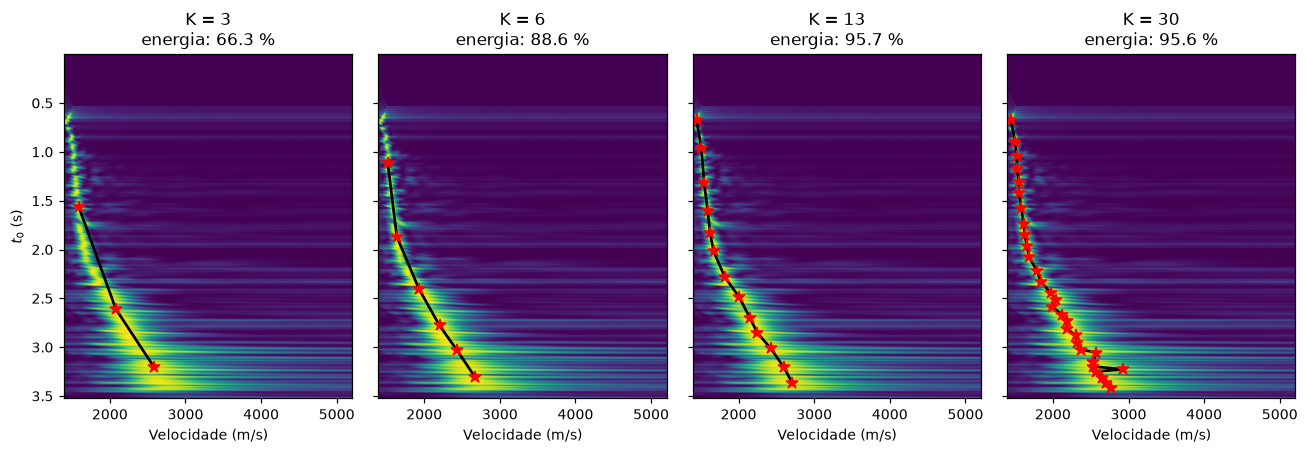

Inicialização original com K = 15: **13 clusters ativos** e 2 vazios, cujos centroides começam em t = 0.22, 0.44 s; o primeiro ponto acima do limiar está em t = 0.61 s. J = 1.59e+08 após 15 iterações e 1.29e+08 após 100, contra 9.95e+07 do k-means++ com K = 13 e 1.31e+08 com K = 11.

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(12, 4.2), sharey=True)
for a, K in zip(ax, [3, 6, 13, 30]):
    plota(a, *res[K][1:], f'K = {K}\nenergia: {energia(*res[K][1:]):.1f} %')
ax[0].set_ylabel('$t_0$ (s)'); plt.tight_layout(); plt.show()

c15, at15, J15 = testes['Com thresholding']
J_conv = kmeans(X_th, maxiter=100)[2]
t_ini = tempo(np.arange(1, 16) * (NT // 16))[~at15]      # tempo inicial dos centroides que ficaram vazios
t_ini = ', '.join(f'{t:.2f}' for t in t_ini)
display(Markdown(
    f'Inicialização original com K = 15: **{at15.sum()} clusters ativos** e {15 - at15.sum()} vazios, '
    f'cujos centroides começam em t = {t_ini} s; o primeiro ponto acima do limiar está em t = {tempo(X_th[:, 1].min()):.2f} s. '
    f'J = {J15[-1]:.2e} após 15 iterações e {J_conv[-1]:.2e} após 100, '
    f'contra {res[13][0]:.2e} do k-means++ com K = 13 e {res[11][0]:.2e} com K = 11.'))

### Resposta

Não há um $K$ "verdadeiro": os pontos formam uma faixa contínua, e não grupos separados. $K$ define a **resolução em tempo** da curva de velocidade e deve ser o **menor valor que descreve a tendência sem criar detalhes sem sentido físico**.

* **Resíduo:** $J$ sempre diminui quando $K$ cresce, então não se escolhe o mínimo. A curva é suave, sem um "cotovelo" nítido; a queda relativa vai de mais de 40 % por cluster (K ≤ 5) para cerca de 10 a 15 % em torno de K = 12 a 17. Sozinho, o critério dá só uma faixa, que depende do que se chama de queda "significativa".
* **Energia capturada:** sobe rápido e satura em torno de 95 % por volta de K = 12. Acima disso, mais clusters quase não melhoram o picking.
* **Física:** de K = 4 a K = 13 a velocidade intervalar máxima fica estável, perto de 4,5 km/s, na parte profunda. Um valor que se repete para tantos K é uma característica do dado. Com K = 14, o menor intervalo entre picks cai de 152 para 96 ms, e o salto para quase 6 km/s aparece exatamente nesse par de picks (2,95 a 3,04 s): é efeito do picking, não da geologia. O padrão se repete: cada novo salto acompanha uma queda do menor intervalo (67 ms em K = 17, 31 ms em K = 25). Com picks tão próximos, pequenas variações horizontais viram velocidades intervalares irreais (acima de 10 km/s) e a curva oscila.
* **K pequeno** (3 a 5) liga poucos pontos por retas longas e perde a curvatura da tendência.

**Escolha: cerca de 12 a 13 clusters** para este dado.

O código do lab, com $K=15$, também termina com 13 clusters ativos, mas isso é coincidência. Os 2 vazios vêm da inicialização: seus centroides começam em 0,22 e 0,44 s, na zona mutada, antes do primeiro ponto acima do limiar (0,61 s). Essa solução também não é um bom ajuste com 13 clusters: o seu J, mesmo após 100 iterações, fica no nível do k-means++ com K = 11 e bem acima do obtido com K = 13. Por isso a escolha de K foi feita com o k-means++, e não com a inicialização original.

Na prática: variar $K$, observar onde $J$ e a energia capturada deixam de melhorar de forma relevante e conferir se a curva resultante é geologicamente aceitável. Em um volume com muitos CMPs, esses critérios podem ser calculados automaticamente para cada um.

## Conclusão

O K-means segue bem a tendência de velocidades quando o *thresholding* isola os máximos de semblance: ele apenas resume a posição desses pontos em $K$ centroides. A qualidade depende, portanto, mais do limiar e da escolha de $K$ do que do algoritmo em si.

Limitações: o limiar é global, e eventos fracos (por exemplo, os rasos) podem ser descartados; múltiplas com semblance alta entrariam no treino, pois não há restrição de velocidade; e o resultado depende da inicialização, que pode deixar clusters vazios. As distâncias usam índices sem normalização: como o eixo do tempo é muito mais longo, os clusters são essencialmente fatias de tempo, o que é conveniente para obter uma curva $V(t_0)$.